# Lucrare de laborator nr. 5: Stable Diffusion în practică

**Student:** Daniel Pănuța, grupa IASD 2501 · **Disciplina:** Inteligența artificială generativă · **Profesor:** V. Ursachi

**Obiectiv:** măsor, prin experimente controlate, cum influențează setările unui model text-imagine preantrenat (Stable Diffusion 1.5) trei lucruri: calitatea imaginii, potrivirea cu textul (scorul CLIP) și timpul de generare.

**Cum funcționează Stable Diffusion**, pe scurt, ca legătură cu Laboratorul 4:

1. **Encoderul de text CLIP** transformă promptul în vectori (77 de tokeni × 768 de valori).
2. **U-Net-ul** face exact ce a făcut rețeaua mea din Lab 4: prezice zgomotul. Diferențele: lucrează în **spațiul latent** (4×64×64 în loc de 3×512×512), iar textul intră prin mecanismul de atenție încrucișată (*cross-attention*).
3. **Programul de eșantionare** (*scheduler*: PNDM, DDIM, DPM-Solver, Euler) decide cum se trece de la un pas la altul, ca DDPM/DDIM din Lab 4.
4. **Decodorul VAE** transformă latentul final în imaginea 512×512.

**Ghidarea fără clasificator** (*classifier-free guidance*): la fiecare pas U-Net-ul se rulează de două ori, cu promptul și fără el. Rezultatul final este

$$\hat\varepsilon = \varepsilon_{\text{fără text}} + s\cdot(\varepsilon_{\text{cu text}} - \varepsilon_{\text{fără text}}),$$

unde $s$ = `guidance_scale` stabilește cât de tare „împinge” textul imaginea.

**Pașii lucrării:**

1. Pregătirea: modelul, cele 3 prompturi și cele 9 imagini de bază.
2. Instrumentele de măsurare: scorul CLIP, timpul pe imagine și funcția `ruleaza`.
3. Experimentele A–E: ghidare, pași, metoda de eșantionare, seed și prompt negativ.
4. Recomandarea: o configurație pentru calitate maximă și una pentru viteză.
5. Bonus: img2img.

La final: întrebările de control și raportul.

## 0. Importuri și dispozitiv

Notebook-ul este rulat pe **Google Colab, GPU T4**, ca în condiție. Am încercat întâi local, pe un MacBook M3 cu 8 GB (backend **MPS**): o imagine de 30 de pași dura 30–55 s, deci toată lucrarea (~3.500 de pași de difuzie) ar fi durat 1,5–2 ore. Codul alege automat `cuda`, `mps` sau `cpu`, iar pe GPU folosește precizia `float16`, deci merge în ambele locuri fără modificări.

- **Instalarea pe Colab:** prima celulă de cod instalează versiunile exacte ale bibliotecilor cu care am scris notebook-ul. Rulează doar pe Colab; local nu face nimic.

- **Generatorul de numere aleatoare:** pe CUDA folosesc `torch.Generator("cuda")`, ca în condiție. Pe MPS biblioteca `diffusers` recomandă un generator pe CPU: zgomotul inițial se creează pe CPU, apoi se mută pe GPU, iar rezultatul rămâne reproductibil.
- **Modul `QUICK`:** dacă variabila de mediu `LAB5_QUICK=1` este setată, notebook-ul rulează o versiune redusă, doar pentru test. Rezultatele de mai jos sunt din rularea completă (`QUICK = False`).

In [1]:
# Doar pe Colab: aceleași versiuni ca la dezvoltare (torchmetrics 1.9 nu merge cu transformers 5)
import sys, subprocess
if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "diffusers==0.39.0", "transformers<5",
                    "huggingface-hub<1", "torchmetrics==1.9.0"], check=True)

In [2]:
import os, json, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from diffusers import (StableDiffusionPipeline, StableDiffusionImg2ImgPipeline,
                       DDIMScheduler, DPMSolverMultistepScheduler, EulerDiscreteScheduler)
from torchmetrics.multimodal.clip_score import CLIPScore
import diffusers, transformers, torchmetrics

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
dtype = torch.float16 if device in ("cuda", "mps") else torch.float32
QUICK = os.environ.get("LAB5_QUICK") == "1"

print(f"PyTorch {torch.__version__} | diffusers {diffusers.__version__} | transformers {transformers.__version__} | torchmetrics {torchmetrics.__version__}")
print("Dispozitiv:", device, "| precizie:", dtype, "| QUICK:", QUICK)

def sync():
    if device == "cuda": torch.cuda.synchronize()
    elif device == "mps": torch.mps.synchronize()

def make_generator(seed):
    gen_device = "cuda" if device == "cuda" else "cpu"
    return torch.Generator(gen_device).manual_seed(seed)

OUT = "outputs"
os.makedirs(f"{OUT}/imagini", exist_ok=True)

PyTorch 2.11.0+cu130 | diffusers 0.39.0 | transformers 4.57.6 | torchmetrics 1.9.0
Dispozitiv: cuda | precizie: torch.float16 | QUICK: False


## Sarcina 1 — Pregătirea

Încarc **Stable Diffusion 1.5** de pe Hugging Face (`stable-diffusion-v1-5/stable-diffusion-v1-5`), în `float16`. Varianta `fp16` a fișierelor are jumătate din dimensiune (~2 GB), deci se descarcă mai repede.

- **Filtrul de siguranță** (*safety checker*) este dezactivat. La un test preliminar a blocat din greșeală imagini perfect inofensive pentru P1 (seed-urile 1 și 2), înlocuindu-le cu imagini negre. O imagine neagră primește un scor CLIP de ~17 în loc de ~30, deci ar fi stricat media și abaterea standard ale experimentelor. Prompturile din condiție sunt inofensive, iar imaginile sunt folosite doar în acest laborator, conform licenței modelului.
- `enable_attention_slicing()` (doar pe Mac) calculează atenția pe bucăți, ca să încapă în cei 8 GB de memorie partajată. Pe T4 (16 GB) nu e nevoie de el, iar fără el generarea e mai rapidă. Am măsurat diferența: cu slicing o imagine de 30 de pași durează ~30–40 s; fără slicing modelul nu mai încape în memorie, sistemul trece pe swap și o imagine durează peste 19 minute (1150–1440 s).

In [3]:
t0 = time.perf_counter()
pipe = StableDiffusionPipeline.from_pretrained(
    "stable-diffusion-v1-5/stable-diffusion-v1-5", torch_dtype=dtype, variant="fp16",
    safety_checker=None, requires_safety_checker=False)
pipe = pipe.to(device)
if device == "mps":
    pipe.enable_attention_slicing()
pipe.set_progress_bar_config(disable=True)
DEFAULT_SCHEDULER = pipe.scheduler            # păstrez metoda implicită, ca s-o pot restaura
print(f"Model încărcat în {time.perf_counter() - t0:.0f} s")
print("Metoda de eșantionare implicită:", type(DEFAULT_SCHEDULER).__name__)
print(f"Parametri U-Net: {sum(p.numel() for p in pipe.unet.parameters())/1e6:.0f} M | "
      f"encoder text: {sum(p.numel() for p in pipe.text_encoder.parameters())/1e6:.0f} M | "
      f"VAE: {sum(p.numel() for p in pipe.vae.parameters())/1e6:.0f} M")

Model încărcat în 29 s
Metoda de eșantionare implicită: PNDMScheduler
Parametri U-Net: 860 M | encoder text: 123 M | VAE: 84 M


**Prompturile** (în engleză, limba în care a fost antrenat modelul) și **configurația de bază**: 30 de pași, scara de ghidare 7,5, rezoluție 512×512, seed-urile 42, 7 și 123.

In [4]:
PROMPTS = {
    "P1": "a watercolor painting of a red fox in a snowy forest",
    "P2": "a photo of a modern library interior, natural light",
    "P3": "a cartoon robot reading a book, flat illustration",
}
SEEDS = [42, 7, 123]
BASE = dict(num_inference_steps=30, guidance_scale=7.5, height=512, width=512,
            scheduler=None, negative_prompt=None)

if QUICK:   # versiune redusă, doar pentru test
    PROMPTS = {"P1": PROMPTS["P1"]}; SEEDS = [42]
    BASE["num_inference_steps"] = 5

## Sarcina 2 — Instrumentele de măsurare

1. **Scorul CLIP** măsoară cât se potrivește imaginea cu textul. Modelul CLIP (`openai/clip-vit-base-patch16`) codifică separat imaginea și textul, iar scorul este $100 \cdot \max(\cos(\text{imagine}, \text{text}), 0)$. Un scor mai mare înseamnă o potrivire mai bună. Încarc metrica **o singură dată** și calculez scorul **pentru fiecare imagine în parte**, ca să pot raporta media și abaterea standard.
2. **Timpul pe imagine:** `time.perf_counter()`, cu sincronizarea GPU-ului înainte de fiecare citire. Cuprinde tot drumul: encoderul de text, toți pașii U-Net-ului și decodorul VAE. Prima generare este o **încălzire** și nu intră în măsurători: la primul apel GPU-ul compilează operațiile și alocă memoria.
3. **Funcția `ruleaza(config)`** generează cele 9 imagini (3 prompturi × 3 seed-uri). Pornește mereu de la configurația de bază `BASE` și schimbă doar ce primește în `config`. Întoarce scorul CLIP mediu, abaterea lui standard, timpul mediu pe imagine și imaginile.

In [5]:
clip_metric = CLIPScore(model_name_or_path="openai/clip-vit-base-patch16")   # pe CPU: păstrez memoria GPU pentru SD

def clip_one(img, text):
    x = torch.from_numpy(np.array(img)).permute(2, 0, 1).unsqueeze(0)   # (1, 3, H, W), uint8
    return float(clip_metric(x, [text]))

SCHEDULERS = {"DDIM": DDIMScheduler, "DPM-Solver": DPMSolverMultistepScheduler, "Euler": EulerDiscreteScheduler}

def set_scheduler(name):
    if name is None:
        pipe.scheduler = DEFAULT_SCHEDULER
    else:
        pipe.scheduler = SCHEDULERS[name].from_config(DEFAULT_SCHEDULER.config)

def genereaza(prompt, seed, cfg):
    sync(); t0 = time.perf_counter()
    out = pipe(prompt, num_inference_steps=cfg["num_inference_steps"], guidance_scale=cfg["guidance_scale"],
               height=cfg["height"], width=cfg["width"], negative_prompt=cfg["negative_prompt"],
               generator=make_generator(seed))
    sync(); dt = time.perf_counter() - t0
    return out.images[0], dt

RESULTS = {}   # numele rulării -> rezultate (fără imagini), salvate și în outputs/results.json

def ruleaza(config, name, prompts=None, seeds=None):
    cfg = {**BASE, **config}
    prompts = prompts or PROMPTS
    seeds = seeds or SEEDS
    set_scheduler(cfg["scheduler"])
    images, scores, times = {}, [], []
    os.makedirs(f"{OUT}/imagini/{name}", exist_ok=True)
    for pk, ptext in prompts.items():
        for s in seeds:
            img, dt = genereaza(ptext, s, cfg)
            img.save(f"{OUT}/imagini/{name}/{pk}_seed{s}.png")
            images[(pk, s)] = img
            scores.append(clip_one(img, ptext)); times.append(dt)
    set_scheduler(None)          # restaurez metoda implicită
    res = dict(clip_mean=float(np.mean(scores)), clip_std=float(np.std(scores, ddof=1)) if len(scores) > 1 else 0.0,
               time_mean=float(np.mean(times)), scores=scores, times=times,
               config={k: v for k, v in cfg.items()})
    RESULTS[name] = res
    json.dump(RESULTS, open(f"{OUT}/results.json", "w"), indent=1)
    print(f"{name:22} CLIP = {res['clip_mean']:.2f} ± {res['clip_std']:.2f} | timp/imagine = {res['time_mean']:.2f} s")
    return {**res, "images": images}

def grila(rows, row_labels, col_labels, title, path, size=2.6):
    # rows: listă de liste de imagini PIL
    nr, nc = len(rows), len(rows[0])
    fig, axes = plt.subplots(nr, nc, figsize=(size * nc, size * nr + 0.6), squeeze=False)
    for i in range(nr):
        for j in range(nc):
            axes[i, j].imshow(rows[i][j].resize((256, 256)))
            axes[i, j].set_xticks([]); axes[i, j].set_yticks([])
            if i == 0: axes[i, j].set_title(col_labels[j], fontsize=10)
        axes[i, 0].set_ylabel(row_labels[i], fontsize=10)
    fig.suptitle(title, fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.97]); plt.savefig(path, dpi=100); plt.show()

**Încălzirea** (nu intră în măsurători) și **cele 9 imagini de bază**:

Generarea de încălzire: 9.7 s (ignorată)


baza                   CLIP = 34.32 ± 2.17 | timp/imagine = 5.36 s


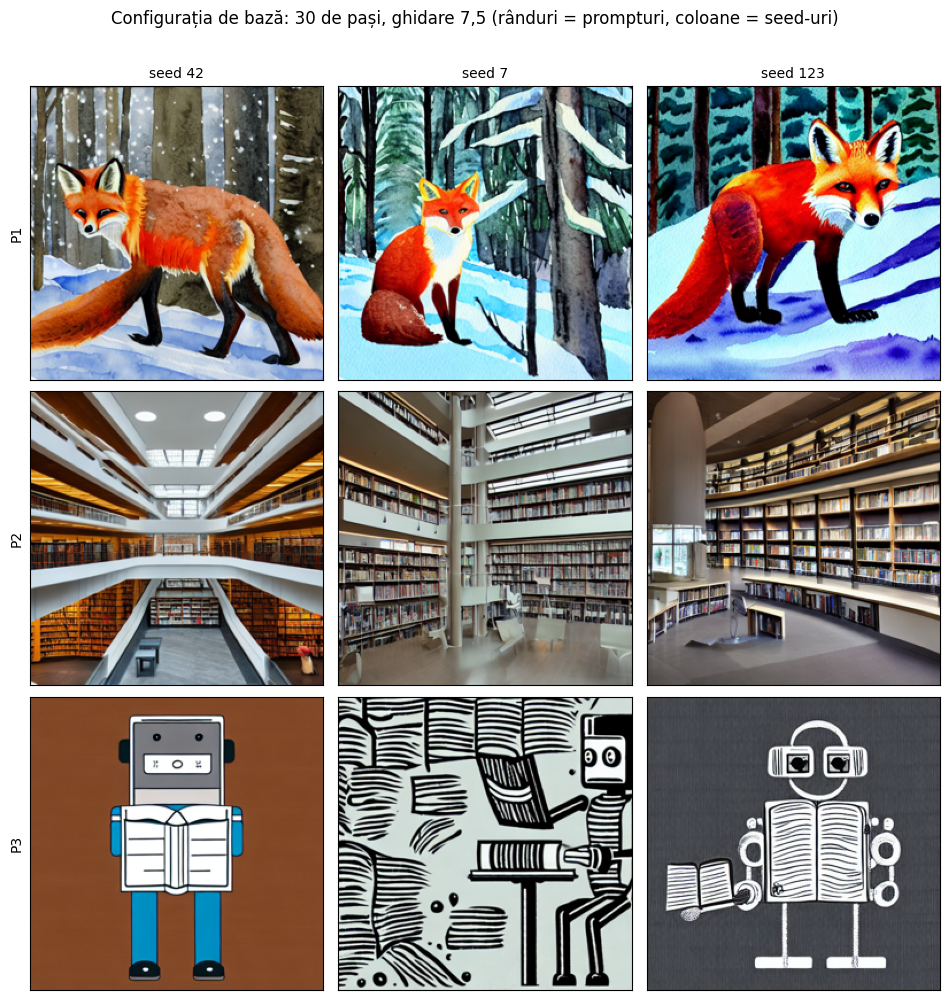

P1 = a watercolor painting of a red fox in a snowy forest
P2 = a photo of a modern library interior, natural light
P3 = a cartoon robot reading a book, flat illustration


In [6]:
_, t_warm = genereaza(PROMPTS["P1"], 0, BASE)
print(f"Generarea de încălzire: {t_warm:.1f} s (ignorată)")

base = ruleaza({}, "baza")
grila([[base["images"][(pk, s)] for s in SEEDS] for pk in PROMPTS],
      [f"{pk}" for pk in PROMPTS], [f"seed {s}" for s in SEEDS],
      "Configurația de bază: 30 de pași, ghidare 7,5 (rânduri = prompturi, coloane = seed-uri)",
      f"{OUT}/s1_baza.png", size=3.2)
for pk, t in PROMPTS.items(): print(pk, "=", t)

**Observații (configurația de bază):** scor CLIP **34,32 ± 2,17**, **5,36 s** pe imagine pe T4.

- **P1 (vulpea în acuarelă):** toate cele 3 seed-uri respectă promptul: vulpe roșie, zăpadă, copaci, aspect de acuarelă. Seed-ul schimbă complet compoziția: vulpe din profil (42), vulpe așezată (7), vulpe privind spre noi, cu umbre albastre pe zăpadă (123).
- **P2 (biblioteca):** arată ca o fotografie, cu mai multe etaje și lumină naturală. Detaliile fine sunt slabe: cotoarele cărților sunt pete de culoare, iar unele rafturi se „topesc” unele în altele.
- **P3 (robotul):** conținutul e corect (robot care citește o carte), dar stilul variază mult. Doar seed-ul 42 e o ilustrație plată colorată. Seed-ul 7 seamănă cu o gravură alb-negru, iar seed-ul 123 cu o schiță pe fundal gri. Textul din cărți nu e lizibil, ca de obicei la SD 1.5.

## Sarcina 3 — Experimentele A–E

Fiecare experiment pornește de la configurația de bază și schimbă **un singur parametru**. Seed-urile rămân aceleași (42, 7, 123).

- Acolo unde valoarea testată coincide cu cea de bază (ghidare 7,5; „fără prompt negativ”), refolosesc rezultatul rulării `baza`: e exact aceeași configurație.
- Pentru grilele comparative afișez, pentru fiecare valoare, cele 3 prompturi cu seed-ul 42. Toate cele 9 imagini ale fiecărei rulări sunt salvate în `outputs/imagini/` și intră în scorul CLIP.

**Atenție la interpretare:** scorul CLIP variază de la o imagine la alta. O diferență între două configurații mai mică decât abaterea standard **nu este concludentă**.

### Experimentul A — scara de ghidare (`guidance_scale` = 1; 3; 7,5; 12; 20)

A_ghidare_1            CLIP = 28.74 ± 4.64 | timp/imagine = 3.89 s
A_ghidare_3            CLIP = 34.09 ± 2.46 | timp/imagine = 6.06 s
A_ghidare_12           CLIP = 33.92 ± 2.37 | timp/imagine = 6.09 s
A_ghidare_20           CLIP = 33.95 ± 2.41 | timp/imagine = 6.11 s


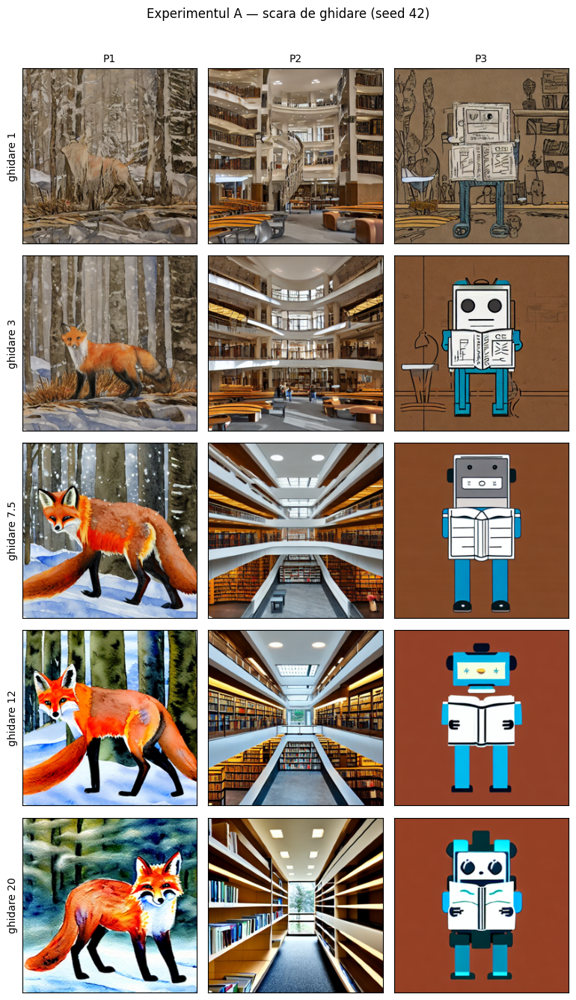

In [7]:
A_VALUES = [1, 3, 7.5, 12, 20] if not QUICK else [1, 7.5]
runs_A = {}
for g in A_VALUES:
    runs_A[g] = base if g == BASE["guidance_scale"] else ruleaza({"guidance_scale": g}, f"A_ghidare_{g}")

grila([[runs_A[g]["images"][(pk, 42)] for pk in PROMPTS] for g in A_VALUES],
      [f"ghidare {g}" for g in A_VALUES], list(PROMPTS), "Experimentul A — scara de ghidare (seed 42)",
      f"{OUT}/exp_A.png")

### Experimentul B — numărul de pași (`num_inference_steps` = 5; 10; 20; 50)

Configurația de bază (30 de pași) apare în grafic ca punct de referință.

B_pasi_5               CLIP = 31.87 ± 3.64 | timp/imagine = 1.37 s
B_pasi_10              CLIP = 33.43 ± 2.67 | timp/imagine = 2.36 s
B_pasi_20              CLIP = 34.99 ± 2.12 | timp/imagine = 4.24 s
B_pasi_50              CLIP = 34.65 ± 1.82 | timp/imagine = 9.83 s


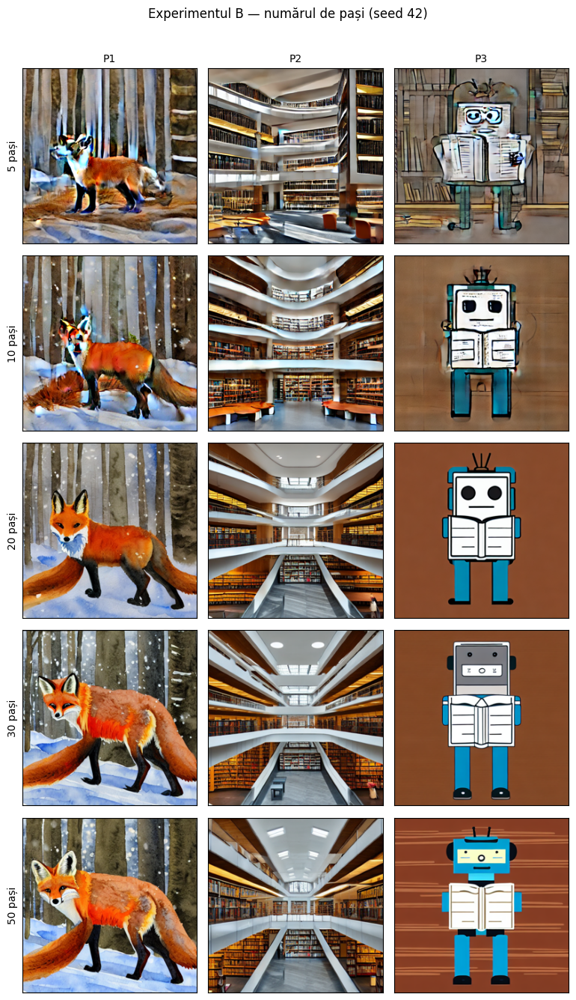

In [8]:
B_VALUES = [5, 10, 20, 50] if not QUICK else [5, 10]
runs_B = {n: ruleaza({"num_inference_steps": n}, f"B_pasi_{n}") for n in B_VALUES}

B_ALL = sorted(B_VALUES + [BASE["num_inference_steps"]])
runs_B_all = {**runs_B, BASE["num_inference_steps"]: base}
grila([[runs_B_all[n]["images"][(pk, 42)] for pk in PROMPTS] for n in B_ALL],
      [f"{n} pași" for n in B_ALL], list(PROMPTS), "Experimentul B — numărul de pași (seed 42)",
      f"{OUT}/exp_B.png")

### Experimentul C — metoda de eșantionare (DDIM, DPM-Solver multistep, Euler; fiecare la 10 și 30 de pași)

Schimb metoda cu `X.from_config(pipe.scheduler.config)`, pornind de la configurația metodei implicite (PNDM), iar după fiecare rulare o restaurez.

C_DDIM_10              CLIP = 34.23 ± 2.10 | timp/imagine = 2.12 s
C_DDIM_30              CLIP = 35.13 ± 2.15 | timp/imagine = 5.92 s
C_DPM-Solver_10        CLIP = 34.92 ± 1.90 | timp/imagine = 2.12 s
C_DPM-Solver_30        CLIP = 35.03 ± 1.99 | timp/imagine = 5.92 s
C_Euler_10             CLIP = 34.21 ± 2.38 | timp/imagine = 2.11 s
C_Euler_30             CLIP = 35.30 ± 1.27 | timp/imagine = 5.94 s


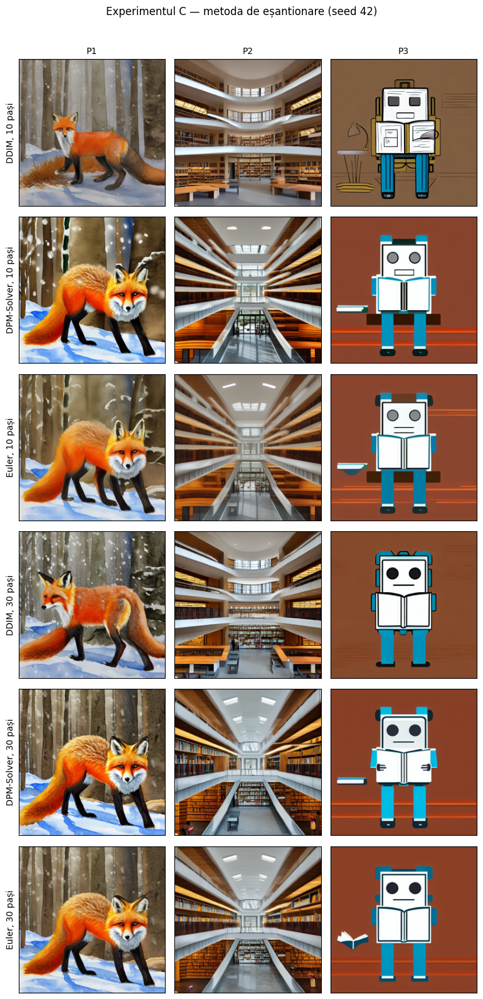

In [9]:
C_STEPS = [10, 30] if not QUICK else [10]
runs_C = {}
for sname in SCHEDULERS:
    for n in C_STEPS:
        runs_C[(sname, n)] = ruleaza({"scheduler": sname, "num_inference_steps": n}, f"C_{sname}_{n}")

keys_C = [(s, n) for n in C_STEPS for s in SCHEDULERS]
grila([[runs_C[k]["images"][(pk, 42)] for pk in PROMPTS] for k in keys_C],
      [f"{s}, {n} pași" for s, n in keys_C], list(PROMPTS), "Experimentul C — metoda de eșantionare (seed 42)",
      f"{OUT}/exp_C.png")

### Experimentul D — seed-ul

1. Același prompt (P1) și aceeași configurație, cu **4 seed-uri diferite** (1, 2, 3, 4): cât de mult variază imaginea doar din zgomotul de pornire?
2. Seed-ul 42 **de două ori**: verific numeric că se obține aceeași imagine. Calculez diferența medie absolută între pixeli (0 = imagini identice, maxim 255).

D_seeduri_P1           CLIP = 35.45 ± 1.42 | timp/imagine = 6.07 s
Seed 42 de două ori: diferența medie între pixeli = 0.0000 (max. diferență pe un pixel: 0)
Seed 42 acum vs. seed 42 din rularea de bază: 0.0000
Pentru comparație, seed 1 vs. seed 2: diferența medie = 91.6


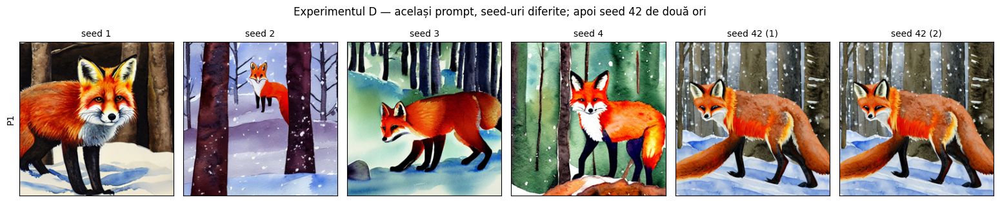

In [10]:
D_SEEDS = [1, 2, 3, 4] if not QUICK else [1, 2]
run_D = ruleaza({}, "D_seeduri_P1", prompts={"P1": PROMPTS["P1"]}, seeds=D_SEEDS)

img_42a, _ = genereaza(PROMPTS["P1"], 42, BASE)
img_42b, _ = genereaza(PROMPTS["P1"], 42, BASE)
a, b = np.asarray(img_42a, dtype=np.float32), np.asarray(img_42b, dtype=np.float32)
diff_42 = float(np.abs(a - b).mean())
diff_base = float(np.abs(a - np.asarray(base["images"][("P1", 42)], dtype=np.float32)).mean())
print(f"Seed 42 de două ori: diferența medie între pixeli = {diff_42:.4f} (max. diferență pe un pixel: {np.abs(a - b).max():.0f})")
print(f"Seed 42 acum vs. seed 42 din rularea de bază: {diff_base:.4f}")
diff_seeds = float(np.abs(np.asarray(run_D['images'][('P1', D_SEEDS[0])], dtype=np.float32) -
                          np.asarray(run_D['images'][('P1', D_SEEDS[1])], dtype=np.float32)).mean())
print(f"Pentru comparație, seed {D_SEEDS[0]} vs. seed {D_SEEDS[1]}: diferența medie = {diff_seeds:.1f}")

grila([[run_D["images"][("P1", s)] for s in D_SEEDS] + [img_42a, img_42b]],
      ["P1"], [f"seed {s}" for s in D_SEEDS] + ["seed 42 (1)", "seed 42 (2)"],
      "Experimentul D — același prompt, seed-uri diferite; apoi seed 42 de două ori", f"{OUT}/exp_D.png")

### Experimentul E — promptul negativ (fără / „blurry, low quality, text, watermark”)

Promptul negativ înlocuiește promptul gol din ghidarea fără clasificator. Ghidarea împinge imaginea **spre** promptul pozitiv și **dinspre** cel negativ.

E_prompt_negativ       CLIP = 34.40 ± 2.39 | timp/imagine = 6.07 s


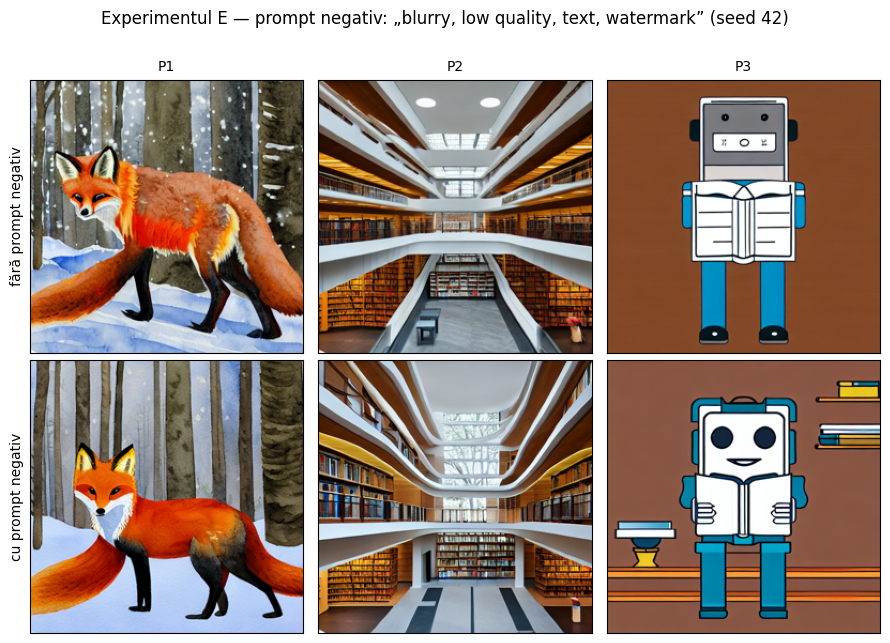

In [11]:
NEG = "blurry, low quality, text, watermark"
run_E = ruleaza({"negative_prompt": NEG}, "E_prompt_negativ")

grila([[base["images"][(pk, 42)] for pk in PROMPTS], [run_E["images"][(pk, 42)] for pk in PROMPTS]],
      ["fără prompt negativ", "cu prompt negativ"], list(PROMPTS), f"Experimentul E — prompt negativ: „{NEG}” (seed 42)",
      f"{OUT}/exp_E.png", size=3.0)

### Tabelul de rezultate și graficele A și B

In [12]:
def row(exp, val, r):
    return {"Experiment": exp, "Valoare": val, "CLIP medie": round(r["clip_mean"], 2), "CLIP abatere": round(r["clip_std"], 2),
            "Scor CLIP (medie ± abatere)": f"{r['clip_mean']:.2f} ± {r['clip_std']:.2f}", "Timp / imagine (s)": round(r["time_mean"], 2)}

rows = [row("Bază", "30 pași, ghidare 7,5", base)]
rows += [row("A", f"ghidare {g}", runs_A[g]) for g in A_VALUES if g != BASE["guidance_scale"]]
rows += [row("B", f"{n} pași", runs_B[n]) for n in B_VALUES]
rows += [row("C", f"{s}, {n} pași", runs_C[(s, n)]) for s, n in keys_C]
rows += [row("D", f"P1, seed-uri {D_SEEDS}", run_D)]
rows += [row("E", "cu prompt negativ", run_E)]
tabel = pd.DataFrame(rows)
tabel.to_csv(f"{OUT}/tabel_rezultate.csv", index=False)
tabel[["Experiment", "Valoare", "Scor CLIP (medie ± abatere)", "Timp / imagine (s)"]]

,Experiment,Valoare,Scor CLIP (medie ± abatere),Timp / imagine (s)
0,Bază,"30 pași, ghidare 7,5",34.32 ± 2.17,5.36
1,A,ghidare 1,28.74 ± 4.64,3.89
2,A,ghidare 3,34.09 ± 2.46,6.06
3,A,ghidare 12,33.92 ± 2.37,6.09
4,A,ghidare 20,33.95 ± 2.41,6.11
5,B,5 pași,31.87 ± 3.64,1.37
6,B,10 pași,33.43 ± 2.67,2.36
7,B,20 pași,34.99 ± 2.12,4.24
8,B,50 pași,34.65 ± 1.82,9.83
9,C,"DDIM, 10 pași",34.23 ± 2.10,2.12


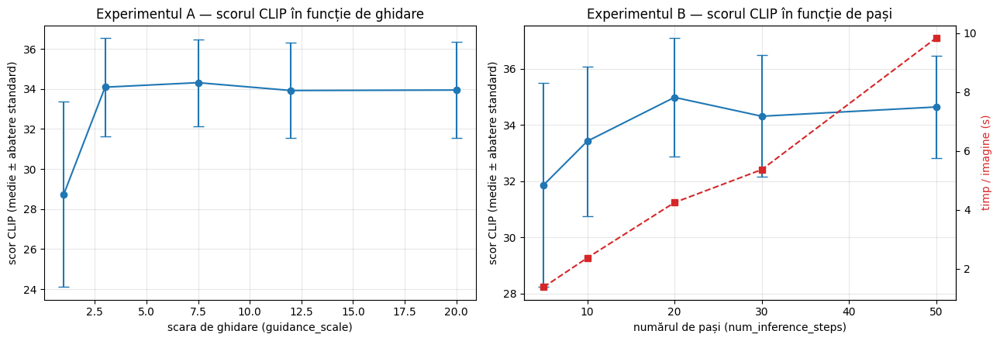

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
gA = A_VALUES
axes[0].errorbar(gA, [runs_A[g]["clip_mean"] for g in gA], yerr=[runs_A[g]["clip_std"] for g in gA],
                 marker="o", capsize=5)
axes[0].set_xlabel("scara de ghidare (guidance_scale)"); axes[0].set_ylabel("scor CLIP (medie ± abatere standard)")
axes[0].set_title("Experimentul A — scorul CLIP în funcție de ghidare"); axes[0].grid(alpha=0.3)

axes[1].errorbar(B_ALL, [runs_B_all[n]["clip_mean"] for n in B_ALL], yerr=[runs_B_all[n]["clip_std"] for n in B_ALL],
                 marker="o", capsize=5, label="scor CLIP")
axes[1].set_xlabel("numărul de pași (num_inference_steps)"); axes[1].set_ylabel("scor CLIP (medie ± abatere standard)")
axes[1].set_title("Experimentul B — scorul CLIP în funcție de pași"); axes[1].grid(alpha=0.3)
ax2 = axes[1].twinx()
ax2.plot(B_ALL, [runs_B_all[n]["time_mean"] for n in B_ALL], color="tab:red", ls="--", marker="s", label="timp / imagine")
ax2.set_ylabel("timp / imagine (s)", color="tab:red")
plt.tight_layout(); plt.savefig(f"{OUT}/grafice_A_B.png", dpi=120); plt.show()

**Tabelul de rezultate cu observațiile vizuale** (9 imagini pe rând, la D doar 4; observațiile se bazează pe grilele de mai sus):

| Experiment | Valoare | Scor CLIP (medie ± abatere) | Timp / imagine (s) | Observații vizuale |
|---|---|---|---|---|
| Bază | 30 pași, ghidare 7,5 | 34,32 ± 2,17 | 5,36 | Imagini curate, toate respectă promptul; stilul la P3 variază de la un seed la altul. |
| A | ghidare 1 | 28,74 ± 4,64 | 3,89 | Imagini spălăcite, gri-maronii; vulpea abia se vede, robotul se pierde în fundal. Mai rapid: fără ghidare, U-Net-ul rulează o singură dată pe pas. |
| A | ghidare 3 | 34,09 ± 2,46 | 6,06 | Conținut corect, dar culori stinse; vulpea e mai realistă decât acuarelă. |
| A | ghidare 12 | 33,92 ± 2,37 | 6,09 | Culori mai saturate și contrast mai mare decât la 7,5; încă natural. |
| A | ghidare 20 | 33,95 ± 2,41 | 6,11 | Suprasaturat, contrast exagerat, forme simplificate; compoziția se schimbă (biblioteca devine un coridor îngust). |
| B | 5 pași | 31,87 ± 3,64 | 1,37 | Neclar, cu artefacte și zgomot rămas; robotul e doar o schiță. |
| B | 10 pași | 33,43 ± 2,67 | 2,36 | Recognoscibil, dar granulat; botul vulpii e deformat, contururile sunt nesigure. |
| B | 20 pași | 34,99 ± 2,12 | 4,24 | Curat, comparabil cu 30 de pași. |
| B | 50 pași | 34,65 ± 1,82 | 9,83 | Nicio îmbunătățire vizibilă față de 20–30; doar detalii diferite. |
| C | DDIM, 10 pași | 34,23 ± 2,10 | 2,12 | Mai moale, cu mai puține detalii; robotul încă are aspect de schiță. |
| C | DPM-Solver, 10 pași | 34,92 ± 1,90 | 2,12 | Deja curat și detaliat, aproape identic cu varianta de 30 de pași. |
| C | Euler, 10 pași | 34,21 ± 2,38 | 2,11 | La fel ca DPM-Solver: aproape identic cu varianta de 30 de pași. |
| C | DDIM, 30 pași | 35,13 ± 2,15 | 5,92 | Curat; foarte asemănător cu baza (PNDM, 30 de pași). |
| C | DPM-Solver, 30 pași | 35,03 ± 1,99 | 5,92 | Curat, blana vulpii foarte detaliată. |
| C | Euler, 30 pași | 35,30 ± 1,27 | 5,94 | Practic aceeași imagine ca DPM-Solver la 30 de pași. |
| D | P1, seed-uri 1–4 | 35,45 ± 1,42 | 6,07 | 4 compoziții complet diferite (prim-plan, vulpe mică în depărtare, fundal verde, vulpe din față). Seed 42 de două ori: diferență **0,0000**. |
| E | cu prompt negativ | 34,40 ± 2,39 | 6,07 | Vulpea mai curată și mai saturată; robotul mai detaliat, cu un decor (rafturi). Timp identic. |

**Ce spun numerele:**

- **Concludente** (diferența e mai mare decât abaterea standard): doar **ghidarea 1** (28,74, cu cea mai mare abatere, 4,64) și, la limită, **5 pași** (31,87) sunt clar mai slabe decât restul.
- **Neconcludente:** toate celelalte configurații au scoruri între 33,4 și 35,5, cu abateri de ~2. Diferențele dintre ele sunt mai mici decât abaterea standard, deci nu pot spune din scorul CLIP că una e mai bună decât alta. De exemplu, „Euler 30 = 35,30” nu e mai bun decât „baza = 34,32”.
- **Timpul** depinde aproape numai de numărul de pași: ~0,19 s pe pas plus ~0,2 s fix (encoderul de text și decodorul VAE). Metoda de eșantionare nu contează (2,11–2,12 s la 10 pași pentru toate trei), pentru că U-Net-ul consumă aproape tot timpul.
- **Variația timpului pe T4:** baza (5,36 s) a rulat imediat după încălzire. Configurațiile identice ca număr de pași, rulate mai târziu (D, E, A la 3–20), au durat ~6,07 s. Diferența de ~0,7 s vine din GPU-ul Colab (frecvență, încălzire), nu din setări.

## Bonus (+1 p) — img2img

`StableDiffusionImg2ImgPipeline` refolosește componentele aceluiași model (`**pipe.components`), deci nu se descarcă nimic în plus. Pornesc de la imaginea de bază P1 / seed 42 (vulpea în acuarelă) și cer **un alt stil**: „an oil painting of a red fox in a snowy forest”. Parametrul `strength` (0,3; 0,6; 0,9) spune cât zgomot se adaugă imaginii de pornire înainte de curățare.

**Legătura cu Laboratorul 4:** img2img este exact procesul direct `q_sample`. Imaginea este dusă (în spațiul latent) la pasul $t \approx \text{strength} \cdot T$, cu $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon$, iar de acolo procesul invers o reconstruiește ghidat de noul prompt. Din cei 30 de pași se rulează doar ultimii $\lfloor 30 \cdot \text{strength} \rfloor$.

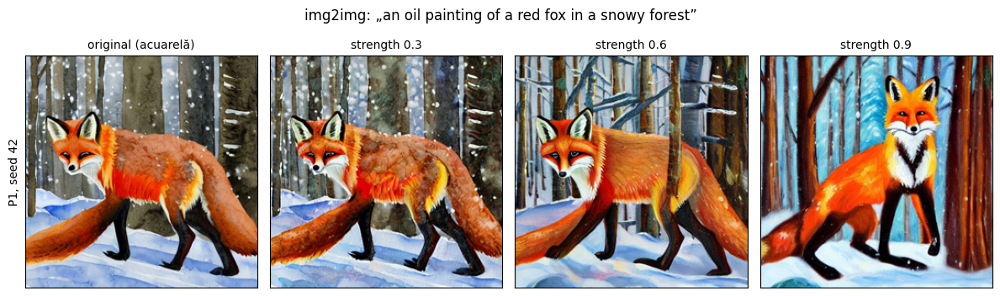

,strength,pași rulați,timp (s),diferență medie față de original,CLIP cu promptul nou,CLIP cu promptul original P1
0,0.3,9,2.36,23.0,36.59,37.43
1,0.6,18,3.97,38.2,36.46,33.72
2,0.9,27,5.74,69.2,36.58,33.54


In [14]:
img2img = StableDiffusionImg2ImgPipeline(**pipe.components)
img2img.set_progress_bar_config(disable=True)
init = base["images"][("P1", 42)]
prompt_i2i = "an oil painting of a red fox in a snowy forest"
STRENGTHS = [0.3, 0.6, 0.9]
outs_i2i, rows_i2i = [], []
for st in STRENGTHS:
    sync(); t0 = time.perf_counter()
    im = img2img(prompt_i2i, image=init, strength=st, num_inference_steps=30, guidance_scale=7.5,
                 generator=make_generator(42)).images[0]
    sync(); dt = time.perf_counter() - t0
    im.save(f"{OUT}/imagini/img2img_strength_{st}.png"); outs_i2i.append(im)
    d = float(np.abs(np.asarray(im, dtype=np.float32) - np.asarray(init, dtype=np.float32)).mean())
    rows_i2i.append({"strength": st, "pași rulați": int(30 * st), "timp (s)": round(dt, 2),
                     "diferență medie față de original": round(d, 1),
                     "CLIP cu promptul nou": round(clip_one(im, prompt_i2i), 2),
                     "CLIP cu promptul original P1": round(clip_one(im, PROMPTS["P1"]), 2)})
grila([[init] + outs_i2i], ["P1, seed 42"], ["original (acuarelă)"] + [f"strength {s}" for s in STRENGTHS],
      f"img2img: „{prompt_i2i}”", f"{OUT}/bonus_img2img.png", size=3.0)
pd.DataFrame(rows_i2i)

**Interpretare:**

- **strength 0,3** (9 pași, 2,36 s): imaginea rămâne aproape aceeași (diferență medie 23,0). Se schimbă doar textura, cu tușe ceva mai groase. Scorul CLIP cu promptul **original** (37,43) e mai mare decât cu cel nou (36,59): imaginea e tot „acuarelă”.
- **strength 0,6** (18 pași, 3,97 s): aceeași poziție a vulpii și aceeași compoziție, dar stilul devine de pictură în ulei (diferență 38,2). Scorul cu promptul nou (36,46) îl depășește acum pe cel cu promptul original (33,72).
- **strength 0,9** (27 de pași, 5,74 s): o imagine nouă. Vulpea stă din față, iar din original rămân doar culorile și ideea de pădure cu zăpadă (diferență 69,2).

**Legătura cu Lab 4:** la strength mic, imaginea e dusă la un pas $t$ mic, unde $\sqrt{\bar\alpha_t}$ e aproape de 1. Zgomotul adăugat e puțin, deci structura originalului supraviețuiește și modelul doar „retușează”. La strength 0,9, $\sqrt{\bar\alpha_t}$ e aproape de 0, iar latentul e aproape zgomot pur. Modelul reconstruiește aproape de la zero, ca la text-to-image. Timpul crește proporțional cu numărul de pași rulați, ca la DDIM în Lab 4.

## Sarcina 4 — Recomandarea

**1. Calitate maximă (timpul nu contează):** **DPM-Solver multistep sau Euler, 30 de pași, ghidare 7,5, cu prompt negativ.**
- La 30 de pași, DPM-Solver și Euler dau imagini curate și detaliate, iar scorul lor CLIP e cel mai mare din tabel: 35,03 și 35,30, cu abaterea cea mai mică la Euler (1,27).
- Peste 20–30 de pași nu am văzut nicio îmbunătățire: 50 de pași costă 9,83 s față de 5,92 s, fără câștig.
- Ghidarea 7,5 e la mijlocul intervalului bun. La 3 culorile sunt stinse, iar la 20 apare suprasaturarea.
- Promptul negativ nu costă timp și, vizual, a făcut imaginile mai curate.
- **Limite:** diferențele CLIP dintre aceste variante și bază sunt mai mici decât abaterea standard. Alegerea se sprijină deci mai ales pe imagini. Combinația „Euler + prompt negativ” nu am testat-o direct, pentru că am schimbat câte un singur parametru.

**2. Viteză (serviciu care răspunde în sub 2 s):** **DPM-Solver multistep, ~8 pași, ghidare 7,5.**
- La 10 pași, DPM-Solver are 34,92 ± 1,90, la fel de bine ca baza (34,32), dar durează **2,12 s** pe T4, puțin peste limită.
- Din măsurători, timpul e ~0,19 s pe pas plus ~0,2 s fix. La 8 pași ar fi deci **~1,7 s**. Aceasta e o estimare, nu am rulat 8 pași.
- Singura configurație măsurată sub 2 s, PNDM cu 5 pași (1,37 s), dă imagini neclare (31,87 ± 3,64), deci nu e acceptabilă.
- Într-un serviciu real, timpul se mai reduce cu un GPU mai rapid decât T4 sau cu ghidarea 1. Ghidarea 1 ar înjumătăți calculul, dar experimentul A arată că strică potrivirea cu textul (28,74), deci nu o recomand.

## Întrebări de control

**1. Ce se întâmplă cu imaginea la ghidare 1 și la ghidare 20? De ce?**

- **La ghidare 1** formula devine $\hat\varepsilon = \varepsilon_{\text{cu text}}$: textul intră în model, dar nu e „amplificat”. Imaginile au ieșit spălăcite și vagi: vulpea abia se vede, robotul se confundă cu fundalul. Scorul CLIP a scăzut la 28,74, cu cea mai mare abatere (4,64). Generarea a fost și mai rapidă (3,89 s față de ~6 s), pentru că `diffusers` nu mai rulează U-Net-ul a doua oară, fără text.
- **La ghidare 20** diferența $(\varepsilon_{\text{cu text}} - \varepsilon_{\text{fără text}})$ e înmulțită de 20 de ori. Predicția iese din zona pe care modelul a văzut-o la antrenare, iar asta dă culori suprasaturate, contrast exagerat și forme simplificate. Scorul CLIP (33,95) nu crește față de 7,5 (34,32): textul nu e „mai respectat”, doar imaginea e mai artificială.

**2. De la câți pași nu mai vedeți îmbunătățiri clare? Coincide cu scorul CLIP?**

Vizual, de la **~20 de pași** (cu PNDM, metoda implicită). La 5 pași imaginea e neclară, la 10 e recognoscibilă dar granulată, iar la 20, 30 și 50 arată la fel de bine, doar cu detalii diferite.

Scorul CLIP spune același lucru: 31,87 → 33,43 → 34,99 → 34,32 → 34,65. Maximul e la 20 de pași, iar diferențele dintre 20, 30 și 50 sunt mai mici decât abaterea standard (~2). Timpul, în schimb, crește liniar până la 9,83 s la 50 de pași.

**3. De ce metodele DPM-Solver și Euler se descurcă mai bine la puțini pași decât DDPM-ul din Laboratorul 4?**

- **DDPM-ul din Lab 4** face 1000 de pași mici și aleatori. Fiecare pas e corect doar dacă diferența dintre $t$ și $t-1$ e foarte mică, așa că pașii nu se pot sări.
- **DPM-Solver și Euler** văd generarea ca pe o **ecuație diferențială** deterministă (*probability-flow ODE*) și o rezolvă numeric cu pași mari:
  - **Euler** e cea mai simplă metodă numerică.
  - **DPM-Solver multistep** calculează exact partea liniară a ecuației. Pentru restul folosește și predicțiile de zgomot de la pașii anteriori, deci e o metodă de ordinul 2: greșește mai puțin la un pas mare.
- **În datele mele:** la 10 pași, DPM-Solver și Euler au dat deja aproape aceeași imagine ca la 30 de pași, deci soluția a convers. DDIM la 10 pași a fost vizibil mai moale. Și DDIM e o metodă deterministă de ordinul 1, ca Euler, iar în Lab 4 a mers bine la 50 de pași, dar mai slab la 10.

**4. De ce același seed dă aceeași imagine? La ce folosește asta în practică?**

Singura sursă de aleatoriu este zgomotul inițial $x_T$ din spațiul latent: 4×64×64 valori, generate din seed. Restul procesului, cu PNDM, DDIM, DPM-Solver sau Euler, este determinist.

Am verificat numeric: seed-ul 42 rulat de două ori dă o diferență medie între pixeli de **0,0000** (maximum 0). Dă aceeași imagine și față de rularea de bază, făcută mai devreme. Pentru comparație, seed 1 față de seed 2 dă o diferență de **91,6**.

**La ce folosește:**
- comparații corecte între setări (toate experimentele mele folosesc aceleași seed-uri);
- reproducerea unui rezultat bun și ajustarea lui fină: prompt, pași, img2img;
- depanarea;
- audit (se poate dovedi cum a fost obținută o imagine).

Limita: identitatea perfectă e garantată doar pe același hardware și cu aceleași versiuni de biblioteci.

**5. Ce nu măsoară scorul CLIP? Dați un exemplu din imaginile voastre.**

Scorul CLIP măsoară doar cât de aproape sunt imaginea și textul în spațiul comun al modelului CLIP. Nu măsoară:
- calitatea estetică;
- artefactele;
- anatomia corectă;
- lizibilitatea textului;
- stilul fin.

**Exemple:**
- **Ghidarea 20** (33,95) are aproape același scor ca 7,5 (34,32), deși e evident suprasaturată.
- **La 10 pași** (33,43), vulpea are botul deformat, iar scorul e în abaterea standard a bazei.
- **La img2img**, imaginea cu strength 0,3, încă acuarelă, primește cu promptul „oil painting” 36,59, practic cât cea cu strength 0,9, care chiar e pictură în ulei (36,58). CLIP nu distinge bine între cele două stiluri.

**6. Ce riscuri etice sau juridice vedeți în folosirea unor astfel de modele într-o companie?**

- **Drepturi de autor:** SD 1.5 e antrenat pe imagini colectate de pe internet (LAION), unele protejate. Imaginile generate pot imita stilul unor artiști în viață sau pot reproduce aproape identic opere existente. Statutul juridic al imaginilor generate e încă neclar.
- **Licența:** modelul are licența CreativeML OpenRAIL-M. Licența interzice anumite utilizări (de exemplu dezinformare, conținut care face rău) și obligă la transmiterea acelorași restricții mai departe.
- **Persoane reale și mărci:** deepfake-uri, folosirea chipului cuiva fără acord, logo-uri ale altor firme.
- **Transparență:** AI Act-ul european cere ca imaginile generate să fie marcate ca atare.
- **Bias:** modelul reproduce stereotipurile din datele de antrenare (gen, etnie, profesii).
- **Siguranță:** în acest laborator am dezactivat filtrul de siguranță, pentru că bloca din greșeală imagini inofensive. Într-un produs public, filtrul trebuie păstrat, iar rezultatele moderate.
- **Date personale:** prompturile utilizatorilor pot conține date personale (GDPR).

## Raport

**Ce am făcut.** Am folosit Stable Diffusion 1.5 (`diffusers`, float16) pe Google Colab, GPU T4, cu PyTorch 2.11, diffusers 0.39.0, transformers 4.57.6 și torchmetrics 1.9.0. Am pornit de la configurația de bază: 30 de pași, ghidare 7,5, 512×512, 3 prompturi × 3 seed-uri. În 5 experimente am schimbat câte un singur parametru, cu aceleași seed-uri. Pentru fiecare configurație am măsurat scorul CLIP (medie ± abatere pe 9 imagini, `openai/clip-vit-base-patch16`) și timpul pe imagine, cu sincronizarea GPU-ului și fără prima generare de încălzire. În total: 17 configurații, ~150 de imagini, plus bonusul img2img.

**Ce am aflat.**

- **Ghidarea** e setarea cu cel mai mare efect. La 1 imaginile ies vagi (CLIP 28,74 ± 4,64). Între 3 și 20 scorul CLIP nu se schimbă semnificativ, dar vizual 20 e suprasaturat. Intervalul bun este 7,5–12.
- **Pașii** contează până la ~20. Mai mult de atât doar costă timp: ~0,19 s pe pas pe T4, liniar.
- **Metoda de eșantionare** nu schimbă timpul pe pas, dar DPM-Solver și Euler ajung deja la 10 pași la o imagine aproape finală. DDIM are nevoie de mai mulți pași.
- **Seed-ul** determină complet imaginea: aceeași configurație cu același seed dă diferență 0,0000, iar seed-uri diferite dau compoziții complet diferite.
- **Promptul negativ** nu costă nimic și a curățat vizual imaginile. Efectul asupra CLIP (34,40 față de 34,32) nu e concludent.

**Recomandarea.** Pentru calitate: DPM-Solver sau Euler, 30 de pași, ghidare 7,5, cu prompt negativ. Pentru viteză (sub 2 s): DPM-Solver la ~8 pași. Am măsurat 2,12 s la 10 pași; 8 pași ar însemna ~1,7 s, estimat.

**Limitări.**

- **Eșantion mic:** 9 imagini pe configurație. Abaterea standard (~2 puncte CLIP) e mai mare decât majoritatea diferențelor dintre configurații, deci acestea nu sunt concludente. Le-am marcat ca atare.
- **Scorul CLIP** nu surprinde calitatea estetică, așa că am completat cu observații vizuale.
- **Timpii pe Colab variază** cu ~0,7 s pentru aceeași configurație (5,36 s la bază, ~6,07 s mai târziu).
- **Filtrul de siguranță** a fost dezactivat, din motivul explicat la Sarcina 1.
- **Prima rulare, local pe un Mac M3 cu 8 GB,** era de 5–10 ori mai lentă (30–55 s pe imagine), din cauza memoriei insuficiente. De aceea rezultatele sunt de pe T4, ca în condiție.